In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from utils import (preprocess_ts,
                   train_with_early_stopping,
                   save_and_plot_data,
                   evaluate, 
                   generate_orbit)

from shallowPLRNN import shallowPLRNN, TimeSeriesDataset
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [96]:
# Parameters
duration = 2  # seconds
sampling_rate = 1000  # Hz
frequency = 10  # Hz
noise_std = 0.0  # standard deviation of observation noise

# Generate time array
t = np.linspace(0, duration, int(duration * sampling_rate))

# Generate sine wave
sine_wave_clean = np.sin(2 * np.pi * frequency * t)

# Add observation noise
np.random.seed(42)  # for reproducibility
noise = np.random.randn(len(sine_wave_clean)) * noise_std
sine_wave = sine_wave_clean + noise

# Time delay embedding function

def time_delay_embedding(signal, N, tau):
    n = len(signal)
    n_samples = n - (N - 1) * tau
    
    if n_samples <= 0:
        raise ValueError("Signal too short for given N and tau")
    
    embedded = np.zeros((n_samples, N))
    for i in range(N):
        embedded[:, i] = signal[i * tau : i * tau + n_samples]
    
    return embedded

# Create embedding
N = 2  # embedding dimension
tau = 10  # lag in samples

embedded = time_delay_embedding(sine_wave, N, tau)

print(f"Original signal shape: {sine_wave.shape}")
print(f"Embedded signal shape: {embedded.shape}")

Original signal shape: (2000,)
Embedded signal shape: (1990, 2)


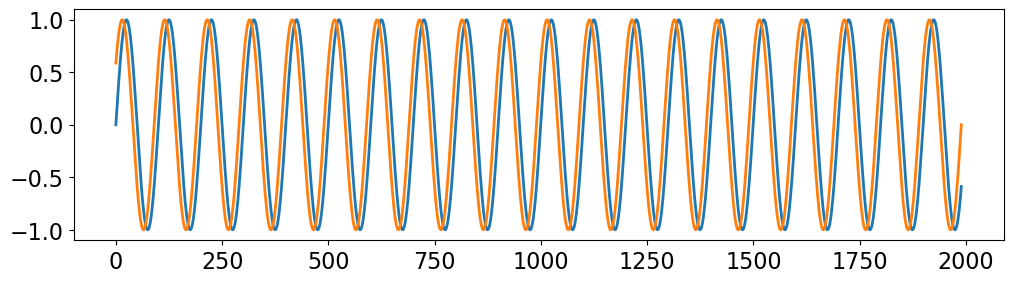

In [98]:
plt.plot(embedded)

In [100]:
parameters = {
            'sequence_length': 32,
            'batch_size': 32,
            'sigma': 0.7,
            'alpha': 0.3,
            'learning_rate': 1e-3,
            'hidden_size': 75,
            'num_epochs': 3000,
            'patience': 3000,
        }
    
cleaned_data = preprocess_ts(embedded, sigma = parameters['sigma'], smooth=False)
data_used = cleaned_data

ntimepoints = data_used.shape[0]
X_train, X_test = data_used[:int(ntimepoints*0.8), :], data_used[int(ntimepoints*0.8):, :]

In [102]:
import matplotlib.pyplot as plt

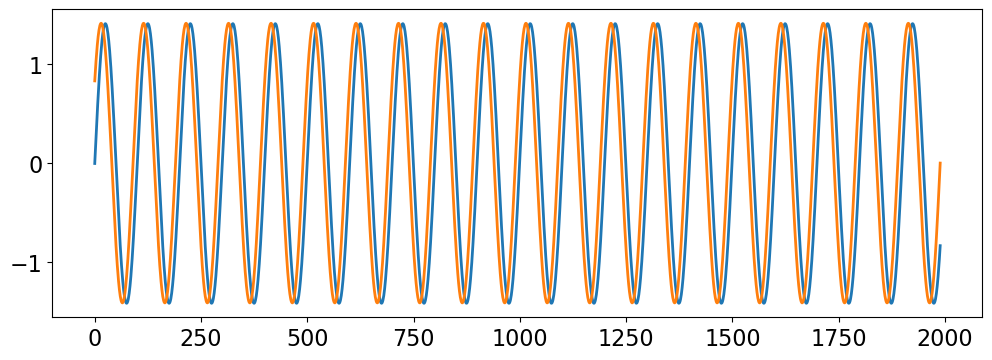

In [104]:
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['font.size'] = 16
plt.rcParams['lines.linewidth'] = 2.
plt.plot(data_used[:,:3])
plt.show()

In [106]:
loss_fn = nn.MSELoss()

In [119]:
model = shallowPLRNN(M=2, L=100, K=0)
optimizer = torch.optim.RAdam(model.parameters(), lr=parameters['learning_rate'], weight_decay=1e-5)

## training

In [122]:
from utils import generate_orbit
from utils import predict_sequence_using_gtf
from tqdm import trange

In [124]:
sequence_length=100
train_ds = TimeSeriesDataset(X_train, sequence_length=parameters['sequence_length'], batch_size=parameters['batch_size'])
test_ds = TimeSeriesDataset(X_test, sequence_length=parameters['sequence_length'], batch_size=parameters['batch_size'])

In [126]:
num_epochs=1000
alpha=0.15
val_ds=test_ds

In [128]:
best_val_loss = float('inf')
epochs_since_improvement = 0
losses = []
best_state = None

model.train()
with trange(num_epochs, unit="batches") as pbar:
    for epoch in pbar:
        optimizer.zero_grad()
        x, y, s = train_ds.sample_batch()
        y_hat = predict_sequence_using_gtf(model, x, s, alpha)
        loss = loss_fn(y_hat, y)
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        if epoch % 10 == 0 or epoch == num_epochs - 1:
            val_loss = evaluate(model, val_ds, loss_fn, alpha)
            pbar.set_postfix(train_loss=loss.item(), val_loss=val_loss)

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                epochs_since_improvement = 0
                best_state = model.state_dict()
            else:
                epochs_since_improvement += 10


# Load best weights
if best_state is not None:
    model.load_state_dict(best_state)

100%|███████████████████████████████████| 1000/1000 [00:19<00:00, 52.04batches/s, train_loss=0.000101, val_loss=9.7e-5]


In [130]:
generated=generate_orbit(model, x[0,0],1000).detach().numpy()

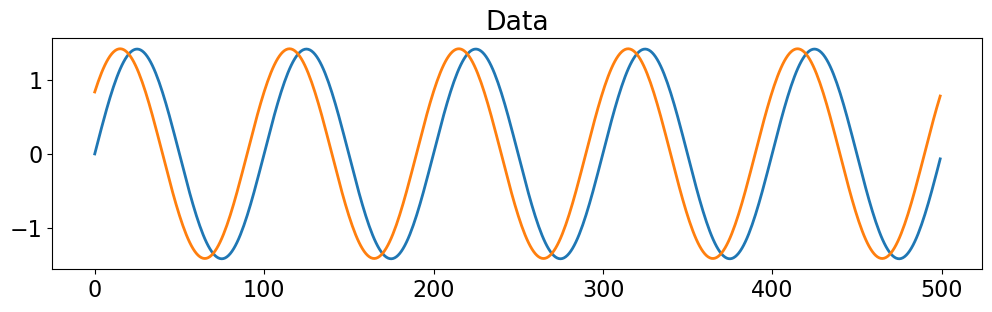

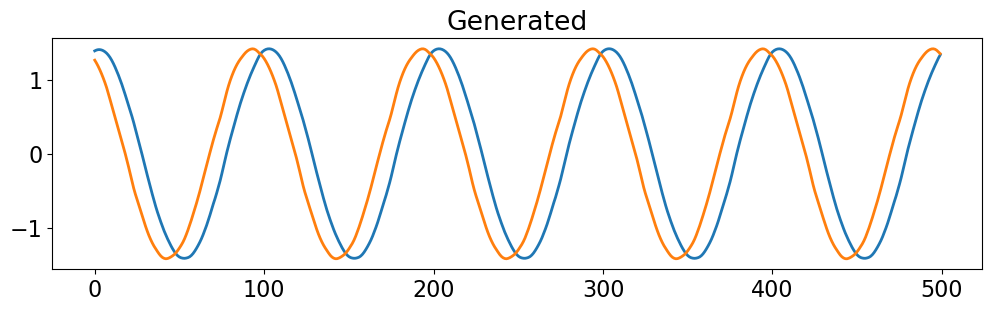

In [132]:
plt.rcParams['figure.figsize'] = (12, 3)
plt.plot(data_used[:500,:5])
#plt.ylim(-4,4)
plt.title("Data")
plt.show()
plt.plot(generated[:500,:5])
plt.title("Generated")
#plt.ylim(-4,4)
plt.show()
